# Data Science II · Pre-entrega 10
## Modelado y evaluación de clasificación binaria — Churn

**Problema de negocio:** identificar clientes con riesgo de abandonar una compañía de telecomunicaciones, para priorizar acciones de retención. **Objetivo (`y`):** `Churn` (1 = abandonó, 0 = permanece).

**Datos de esta ejecución:** 2.400 clientes **simulados** y generados con semilla fija; NO son datos reales ni pertenecen a una empresa. Mantienen los nombres de columnas de la muestra clásica [IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv). La muestra pública de IBM puede descargarse opcionalmente con `py descargar_ibm.py` y sustituir la ruta de lectura. **No atribuir a IBM los resultados obtenidos con datos simulados.**

**Metodología:** análisis de entrada → partición estratificada 80/20 → preprocesamiento dentro de `Pipeline` → regresión logística → predicciones → Accuracy, Precision, Recall y F1 → matriz de confusión → interpretación comercial.

### 1. Bibliotecas y configuración
Trabajamos desde la raíz del repositorio o desde la carpeta `notebooks/`. No se requiere conexión a Internet para esta ejecución.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.dummy import DummyClassifier

PROYECTO = Path.cwd()
if PROYECTO.name == "notebooks":
    PROYECTO = PROYECTO.parent
sys.path.insert(0, str(PROYECTO))
from src.modelado import cargar_datos, construir_pipeline, evaluar, NUMERICAS, CATEGORICAS
print("Notebook listo:", PROYECTO)


Notebook listo: /mnt/data/dsii_pre10_build


### 2. Carga de datos y revisión inicial
Se excluye `customerID` como predictor: es un identificador y no representa una característica de negocio. `TotalCharges` se convierte a numérico; los faltantes se imputarán **después** del split para evitar fuga de información.

In [2]:
RUTA = PROYECTO / "datos" / "clientes_churn_simulados.csv"
# Para utilizar la muestra de IBM ya descargada, reemplazá por:
# RUTA = PROYECTO / "datos" / "Telco-Customer-Churn-IBM.csv"
X, y, df = cargar_datos(RUTA)
print("Filas y columnas:", df.shape)
print("Distribución de churn:")
display(y.map({0: "Permanece", 1: "Abandona"}).value_counts().to_frame("clientes"))
print("Nulos por columna (solo variables con faltantes):")
display(X.isna().sum().loc[lambda s: s > 0].to_frame("faltantes"))
print("Variables numéricas:", NUMERICAS)
print("Variables categóricas:", CATEGORICAS)
display(df[["customerID", "tenure", "Contract", "MonthlyCharges", "Churn"]].head())

Filas y columnas: (2400, 21)
Distribución de churn:


,clientes
Churn,
Permanece,1626
Abandona,774


Nulos por columna (solo variables con faltantes):


,faltantes
MonthlyCharges,30
TotalCharges,15
PaymentMethod,24


Variables numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Variables categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,customerID,tenure,Contract,MonthlyCharges,Churn
0,SIM-000001,57,Month-to-month,55.39,No
1,SIM-000002,54,One year,80.21,No
2,SIM-000003,47,Month-to-month,93.54,Yes
3,SIM-000004,14,Month-to-month,61.67,No
4,SIM-000005,19,Two year,57.73,No


### 3. Partición de entrenamiento y prueba (80/20)
`stratify=y` conserva la proporción de abandono en ambos conjuntos. **Todavía no se ajustó ningún imputador, escalador ni codificador**; todas esas transformaciones se aprenderán únicamente con `X_train`.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))
print("Tasa churn train:", round(y_train.mean(), 4))
print("Tasa churn test:", round(y_test.mean(), 4))
assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))

Entrenamiento: 1920 | Prueba: 480
Tasa churn train: 0.3224
Tasa churn test: 0.3229


### 4. Modelo y entrenamiento
Regresión logística con `class_weight='balanced'` como aproximación inicial, dada la importancia de no omitir clientes que abandonan. Dentro del pipeline se ejecutan: **mediana + estandarización** para variables numéricas, **moda + OneHotEncoder** para categóricas (`handle_unknown='ignore'`).

In [4]:
modelo = construir_pipeline()
print(modelo)
modelo.fit(X_train, y_train)  # El preprocesamiento se ajusta solo con X_train
pred = modelo.predict(X_test)
prob = modelo.predict_proba(X_test)[:, 1]
print("Predicciones calculadas:", len(pred))
assert len(pred) == len(X_test)

Pipeline(steps=[('preprocesador',
                 ColumnTransformer(transformers=[('numerico',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges',
                                                   'SeniorCitizen']),
                                                 ('categorico',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
               

### 5. Métricas sobre datos NO utilizados en entrenamiento
La clase positiva es `Churn=1`. **Precision** indica qué proporción de alertas corresponde a abandono; **Recall**, cuántos abandonos detectamos; **Accuracy**, el acierto global; **F1**, el equilibrio entre Precision y Recall.

In [5]:
metricas = evaluar(y_test, pred)
tabla_metricas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision (churn)", "Recall (churn)", "F1-score (churn)"],
    "Resultado": [metricas["accuracy"], metricas["precision"], metricas["recall"], metricas["f1"]]
})
display(tabla_metricas.style.format({"Resultado": "{:.2%}"}))
print("Reporte completo (por clase):")
print(classification_report(y_test, pred, labels=[0,1], target_names=["Permanece", "Abandona"], zero_division=0))

,Métrica,Resultado
0,Accuracy,67.92%
1,Precision (churn),50.23%
2,Recall (churn),71.61%
3,F1-score (churn),59.04%


Reporte completo (por clase):
              precision    recall  f1-score   support

   Permanece       0.83      0.66      0.74       325
    Abandona       0.50      0.72      0.59       155

    accuracy                           0.68       480
   macro avg       0.67      0.69      0.66       480
weighted avg       0.72      0.68      0.69       480



### 6. Matriz de confusión
Se interpreta por **filas reales** y **columnas predichas**. Los **falsos negativos (FN)** son clientes que efectivamente abandonan pero el modelo etiqueta como que permanecerán; estos casos representan oportunidades de retención perdidas.

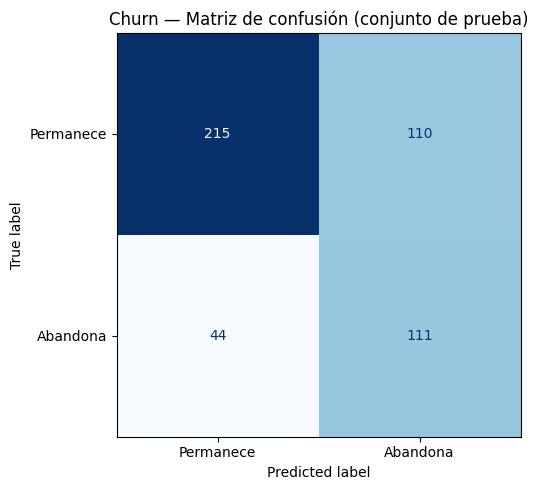

TN=215  FP=110  FN=44  TP=111


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.0))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, labels=[0,1], display_labels=["Permanece", "Abandona"],
    cmap="Blues", values_format="d", ax=ax, colorbar=False
)
ax.set_title("Churn — Matriz de confusión (conjunto de prueba)")
fig.tight_layout()
fig.savefig(PROYECTO / "evidencia" / "matriz_confusion.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"TN={metricas['tn']}  FP={metricas['fp']}  FN={metricas['fn']}  TP={metricas['tp']}")

### 7. Comparación con una línea base
Si pronosticáramos que **ningún** cliente abandona, podríamos lograr un Accuracy aparente razonable por el desbalance de clases, pero un Recall del 0% para Churn. Se incluye una referencia para evitar interpretar únicamente Accuracy.

In [7]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
ref = evaluar(y_test, baseline.predict(X_test))
display(pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1"],
    "Baseline siempre No": [ref["accuracy"], ref["precision"], ref["recall"], ref["f1"]],
    "Regresión logística": [metricas["accuracy"], metricas["precision"], metricas["recall"], metricas["f1"]],
}).round(4))

,Métrica,Baseline siempre No,Regresión logística
0,Accuracy,0.6771,0.6792
1,Precision,0.0000,0.5023
2,Recall,0.0000,0.7161
3,F1,0.0000,0.5904


### 8. Interpretación para el negocio y conclusión

La **métrica prioritaria es Recall sobre la clase `Churn=1`**, porque un **falso negativo** significa que el cliente abandona sin ser detectado y sin que se le pueda ofrecer una acción preventiva. En cambio, un **falso positivo** implica contactar o incentivar a una persona que probablemente permanecería, lo que genera un costo de campaña, pero podría ser menor que el valor perdido por una baja. Esta prioridad **debe verificarse con costos reales**, presupuesto y capacidad del equipo comercial. Por eso también observamos Precision y F1: un Recall alto obtenido a fuerza de alertar a casi todos sería poco eficiente.

**Resultados reproducibles sobre el conjunto simulado de prueba (n=480):** Accuracy **67.92%**, Precision **50.23%**, Recall **71.61%**, F1 **59.04%**. La matriz presenta **111** abandonos correctamente detectados, **44** abandonos no detectados y **110** alertas falsas. El clasificador detecta una proporción importante de clientes que se van, a cambio de contactos innecesarios. El umbral de 0,5 y `class_weight='balanced'` son puntos de partida: en producción convendría calibrar probabilidades, probar otros umbrales sobre validación separada y estimar el beneficio económico.

**Alcance y límites:** los datos son **sintéticos**, por lo cual estas métricas **no predicen el rendimiento de un operador real**; además, se realizó una división aleatoria estratificada de un solo corte de datos, no una validación temporal ni una prueba de impacto causal de campañas. Una empresa debería medir calidad y deriva de datos, definir el instante en que las variables están disponibles y validar el modelo con nuevos periodos antes de usarlo operativamente.

### 9. Control final de coherencia
No se utilizó el conjunto de prueba para ajustar el preprocesador. El resultado puede verificarse ejecutando desde la raíz `py ejecutar.py` y `py -m unittest discover -s tests -v`. La muestra de IBM es una fuente de referencia; **esta ejecución utiliza la muestra simulada**.

In [8]:
assert metricas["tp"] + metricas["fn"] == int(y_test.sum())
assert sum(metricas[k] for k in ["tn", "fp", "fn", "tp"]) == len(y_test)
print("VALIDACIONES FINALES: OK")

VALIDACIONES FINALES: OK
